[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DevDeepakBhattarai/ml-notebooks-2023/blob/main/Transformer_Image_Model.ipynb)

In [1]:
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/

In [3]:

!kaggle datasets download -d hsankesara/flickr-image-dataset

100% 8.16G/8.16G [06:38<00:00, 22.7MB/s]
100% 8.16G/8.16G [06:38<00:00, 22.0MB/s]


In [4]:
import zipfile
zip_ref = zipfile.ZipFile('/content/flickr-image-dataset.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [5]:
folder_path='/content/flickr30k_images/flickr30k_images'

In [6]:
import pandas as pd
unprocessed_df=pd.read_csv('/content/flickr30k_images/results.csv',delimiter='|')
unprocessed_df.drop(columns=' comment_number', inplace=True)
unprocessed_df[' comment'] = unprocessed_df[' comment'].apply(lambda x: ("startseq "+ str(x) + " endseq") if type(x) != str else "startseq "+ x + " endseq")
print(unprocessed_df.shape)
unprocessed_df.head()

(158915, 2)


,image_name,comment
0,1000092795.jpg,startseq Two young guys with shaggy hair look...
1,1000092795.jpg,"startseq Two young , White males are outside ..."
2,1000092795.jpg,startseq Two men in green shirts are standing...
3,1000092795.jpg,startseq A man in a blue shirt standing in a ...
4,1000092795.jpg,startseq Two friends enjoy time spent togethe...


In [7]:
train_y=unprocessed_df[" comment"].values
print(train_y)


['startseq  Two young guys with shaggy hair look at their hands while hanging out in the yard . endseq'
 'startseq  Two young , White males are outside near many bushes . endseq'
 'startseq  Two men in green shirts are standing in a yard . endseq' ...
 'startseq  A man is leaning off of the side of a blue and white boat as it sits in a body of water . endseq'
 'startseq  A man riding a small boat in a harbor , with fog and mountains in the background . endseq'
 'startseq  A man on a moored blue and white boat with hills and mist in the background . endseq']


In [8]:
from tensorflow.keras.preprocessing.text import Tokenizer
tokenizer = Tokenizer()
tokenizer.fit_on_texts(train_y)

In [9]:
print(len(tokenizer.word_index))
vocab_size=len(tokenizer.word_index) +1
tokenizer.word_index

18315


{'a': 1,
 'startseq': 2,
 'endseq': 3,
 'in': 4,
 'the': 5,
 'on': 6,
 'and': 7,
 'man': 8,
 'is': 9,
 'of': 10,
 'with': 11,
 'woman': 12,
 'two': 13,
 'are': 14,
 'to': 15,
 'people': 16,
 'at': 17,
 'an': 18,
 'wearing': 19,
 'shirt': 20,
 'white': 21,
 'young': 22,
 'black': 23,
 'while': 24,
 'his': 25,
 'blue': 26,
 'red': 27,
 'girl': 28,
 'sitting': 29,
 'men': 30,
 'boy': 31,
 'standing': 32,
 'dog': 33,
 'playing': 34,
 'street': 35,
 'group': 36,
 'down': 37,
 'front': 38,
 'her': 39,
 'walking': 40,
 'holding': 41,
 'one': 42,
 'water': 43,
 'three': 44,
 'by': 45,
 'women': 46,
 'green': 47,
 'up': 48,
 'looking': 49,
 'child': 50,
 'as': 51,
 'for': 52,
 'little': 53,
 'large': 54,
 'outside': 55,
 'brown': 56,
 'yellow': 57,
 'person': 58,
 'children': 59,
 'through': 60,
 'hat': 61,
 'from': 62,
 'their': 63,
 'other': 64,
 'ball': 65,
 'small': 66,
 'next': 67,
 'into': 68,
 'over': 69,
 'some': 70,
 'dressed': 71,
 'out': 72,
 'another': 73,
 'running': 74,
 'building

In [10]:
tokenized_sentences=tokenizer.texts_to_sequences(train_y)
tokenized_sentences

[[2, 13, 22, 327, 11, 2039, 89, 188, 17, 63, 160, 24, 325, 72, 4, 5, 491, 3],
 [2, 13, 22, 21, 711, 14, 55, 80, 195, 1428, 3],
 [2, 13, 30, 4, 47, 224, 14, 32, 4, 1, 491, 3],
 [2, 1, 8, 4, 1, 26, 20, 32, 4, 1, 713, 3],
 [2, 13, 489, 814, 590, 9849, 139, 3],
 [2, 120, 30, 4, 328, 273, 14, 1313, 1, 815, 3854, 2641, 3],
 [2, 217, 188, 37, 62, 48, 317, 6, 1, 305, 10, 424, 3],
 [2, 13, 30, 114, 6, 1, 395, 19, 328, 273, 3],
 [2, 111, 30, 6, 100, 10, 1, 412, 511, 3],
 [2, 44, 30, 6, 1, 54, 4738, 3],
 [2, 1, 50, 4, 1, 86, 117, 9, 246, 48, 1, 354, 10, 407, 4, 18, 5158, 635, 3],
 [2, 1, 53, 28, 4, 1, 86, 117, 346, 68, 1, 225, 3519, 3],
 [2, 1, 53, 28, 246, 5, 407, 15, 39, 3743, 3],
 [2, 1, 53, 28, 246, 68, 1, 225, 3743, 3],
 [2, 1, 28, 346, 68, 1, 225, 75, 3],
 [2, 280, 4, 1, 26, 20, 7, 61, 9, 32, 6, 2794, 7, 366, 227, 1, 232, 3],
 [2, 1, 8, 4, 1, 26, 20, 9, 32, 6, 1, 570, 486, 1, 232, 3],
 [2, 1, 8, 6, 1, 570, 1652, 5, 232, 10, 1, 412, 75, 3],
 [2, 8, 4, 26, 20, 7, 133, 6, 570, 486, 852, 3],
 [

In [11]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
padded_seq=pad_sequences(tokenized_sentences,padding="post")

In [12]:
max_comment_length=max([len(sentence) for sentence in tokenized_sentences])
max_comment_length

80

In [13]:
sequence_df=pd.DataFrame({'text':[seq for seq in padded_seq]})

In [14]:
df=pd.concat([unprocessed_df['image_name'],sequence_df],axis=1)
df.head()

,image_name,text
0,1000092795.jpg,"[2, 13, 22, 327, 11, 2039, 89, 188, 17, 63, 16..."
1,1000092795.jpg,"[2, 13, 22, 21, 711, 14, 55, 80, 195, 1428, 3,..."
2,1000092795.jpg,"[2, 13, 30, 4, 47, 224, 14, 32, 4, 1, 491, 3, ..."
3,1000092795.jpg,"[2, 1, 8, 4, 1, 26, 20, 32, 4, 1, 713, 3, 0, 0..."
4,1000092795.jpg,"[2, 13, 489, 814, 590, 9849, 139, 3, 0, 0, 0, ..."


In [15]:
import pickle
tokenizer_save_path = '/content/drive/My Drive/tokenizer.pickle'
with open(tokenizer_save_path, 'wb') as file:
    pickle.dump(tokenizer, file)

In [16]:
import math
valid_size =int(math.floor(0.2 * len(df)))
test_size= int(math.floor(0.1 * len(df)))
sampled_df=df.sample(frac=1, random_state=0)
train_df = sampled_df.iloc[ : len(df) - valid_size]
valid_df = sampled_df.iloc[len(df)- valid_size : len(df) - test_size ]
test_df = sampled_df.iloc[len(df) - test_size : ]

len(train_df) ,len(valid_df),len(test_df)

(127132, 15892, 15891)

In [17]:
train_df.head()
# valid_df.head()
test_df.head()

,image_name,text
97542,4383233985.jpg,"[2, 5, 813, 14, 1252, 4, 1, 721, 326, 3, 0, 0,..."
30231,2454932897.jpg,"[2, 1, 151, 31, 722, 4, 1, 309, 11, 1, 275, 50..."
81985,3689613539.jpg,"[2, 1, 8, 9, 114, 6, 70, 1047, 4, 1, 193, 11, ..."
18203,2135502491.jpg,"[2, 2630, 6285, 33, 74, 4, 5, 324, 81, 3, 0, 0..."
111542,4695761782.jpg,"[2, 56, 205, 12, 40, 7, 589, 17, 98, 3, 0, 0, ..."


In [18]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense , LSTM , Conv2D, MaxPool2D ,Flatten, Embedding ,RepeatVector , Dropout ,Input ,Add,MultiHeadAttention , LayerNormalization,Reshape

In [19]:
from PIL import Image
from tensorflow.keras.utils import to_categorical
def generate_batches(dataframe, batch_size):
    image_names = dataframe['image_name'].values
    texts = np.array(dataframe['text'].values.tolist())

    num_samples = len(dataframe)
    steps_per_epoch = num_samples // batch_size

    for step in range(steps_per_epoch):
        start = step * batch_size
        end = (step + 1) * batch_size

        batch_image_name = image_names[start:end]
        batch_texts = np.array(texts[start:end])

        batch_images = np.array([ np.array(Image.open(folder_path + "/"+ image_name).convert('RGB').resize((256, 256))) / 255 for image_name in batch_image_name])

        categorical_text=to_categorical(batch_texts,num_classes=vocab_size)
        categorical_text=categorical_text[:,1:]
        categorical_text = np.concatenate([categorical_text , np.zeros((categorical_text .shape[0], 1, categorical_text .shape[2]))], axis=1)


        yield [batch_images, batch_texts],categorical_text



In [20]:
def transformer_decoder(embedding_input,encoder_ouput, head_size, num_heads, ff_dim,d_model, dropout=0):

    attention_output ,attention_score= MultiHeadAttention(
        num_heads=num_heads,
        key_dim=head_size,
    )(embedding_input,embedding_input, return_attention_scores=True,use_causal_mask=True )
    normalized_attension = LayerNormalization(epsilon=1e-6)(embedding_input + attention_output)

    cross_attention,cross_attention_score=MultiHeadAttention(
        num_heads=num_heads,
        key_dim=head_size,
    )(query=normalized_attension,value=encoder_ouput,return_attention_scores=True, use_causal_mask=False)
    normalized_cross_attension=LayerNormalization(epsilon=1e-6)(normalized_attension + cross_attention)

    feedforward_output = Dense(ff_dim, activation="relu")(normalized_cross_attension)
    feedforward_output = Dropout(dropout)(feedforward_output)
    feedforward_output=Dense(d_model,activation='relu')(feedforward_output)
    feedforward_output = Dropout(dropout)(feedforward_output)

    transformer_output = LayerNormalization(epsilon=1e-6)(feedforward_output + normalized_cross_attension)

    return transformer_output

def positional_encoding(max_len, d_model):
    position = tf.range(max_len, dtype=tf.float32)[:, tf.newaxis]
    div_term = tf.pow(10000.0, 2 * tf.range(d_model // 2, dtype=tf.float32) / tf.cast(d_model, dtype=tf.float32))
    pos_enc = tf.concat([tf.sin(position / div_term), tf.cos(position / div_term)], axis=-1)
    pos_enc = pos_enc[tf.newaxis, ...]
    return pos_enc

@tf.keras.saving.register_keras_serializable()
class PositionalEncoding(tf.keras.layers.Layer):
    def __init__(self, max_len, d_model):
        super(PositionalEncoding, self).__init__()
        self.pos_encoding = positional_encoding(max_len, d_model)

    def call(self, x):
        return x + self.pos_encoding[:, :tf.shape(x)[1], :]


In [ ]:
# Model values
d_model=512
num_heads=8
num_of_decoder_block=5
dropout=0.4
head_size=64
ff_dim=2048
max_length=max_comment_length
#image_encoder
image_input=Input(shape=(256,256,3))
conv_base=VGG16(
    include_top=False,
    input_shape=(256,256,3),
    weights='imagenet'
)
conv_base.trainable = False
conv_base=conv_base(image_input)
flatten=Flatten()(conv_base)
dense1=Dense(d_model ,activation='relu')(flatten)
dense1=Dropout(dropout)(dense1) # 1 x 512

dense1=Reshape((-1,512))(dense1)

# Text input part
text_input=Input(shape=(max_length,)) # 80 x 512 : max_seq_length x embedding_size
embedding=Embedding(vocab_size,d_model)(text_input)
positional_encoding_values=PositionalEncoding(max_length,d_model)(embedding)
x=positional_encoding_values
for _ in range(num_of_decoder_block):
  x=transformer_decoder(x, dense1 ,d_model=512 ,dropout=dropout,ff_dim=ff_dim,head_size=head_size,num_heads=num_heads )

output = Dense(vocab_size, activation='softmax')(x)
model=Model(inputs=[image_input,text_input],outputs=[output])

model.summary()

58889256/58889256 [==============================] - 0s 0us/step
Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_3 (InputLayer)        [(None, 80)]                 0         []                            
                                                                                                  
 input_1 (InputLayer)        [(None, 256, 256, 3)]        0         []                            
                                                                                                  
 embedding (Embedding)       (None, 80, 512)              9377792   ['input_3[0][0]']             
                                                                                                  
 vgg16 (Functional)          (None, 8, 8, 512)            1471468   ['input_1[0][0]']             
                             

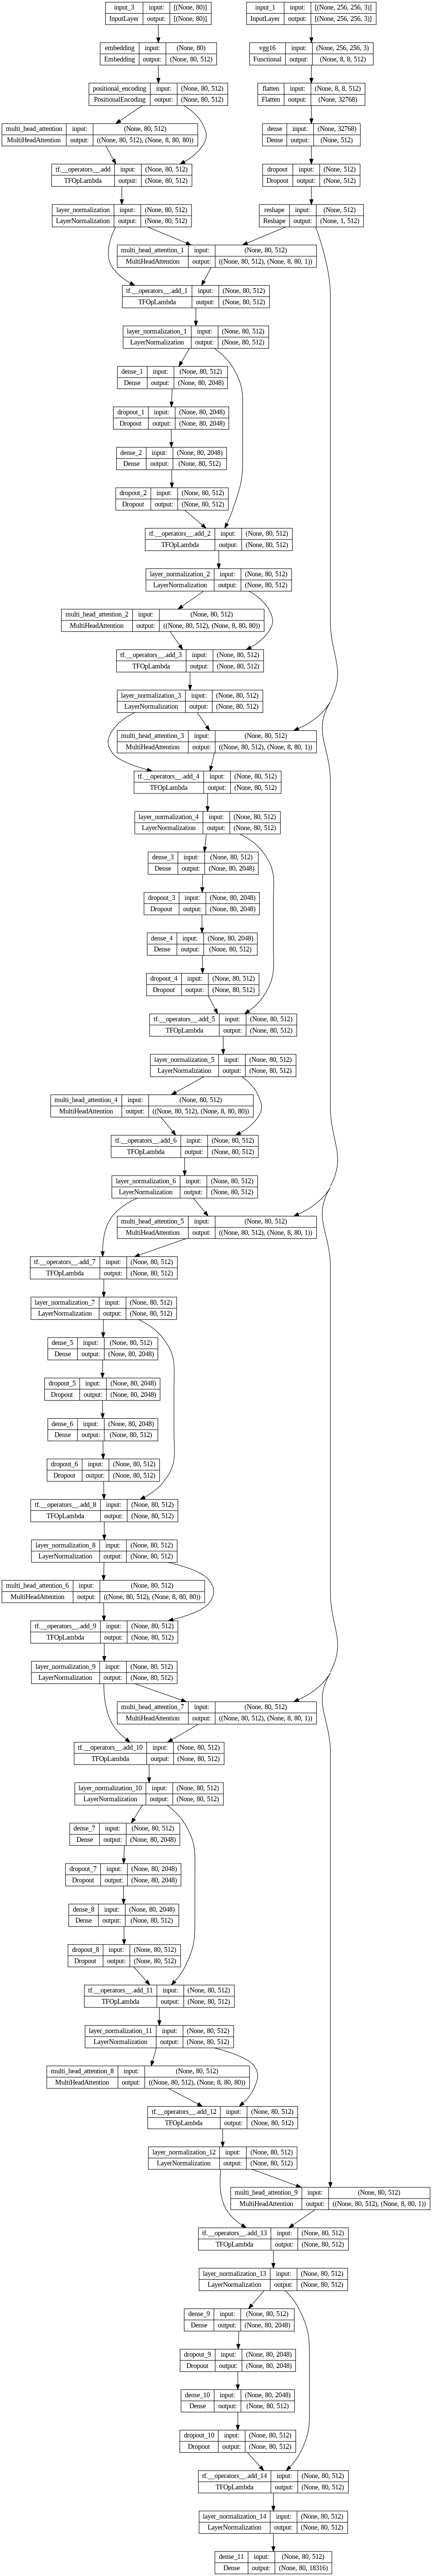

In [ ]:
# from tensorflow.keras.utils import plot_model

# # Assuming you already have the trained ImageCaptioningModel
# # If not, you should load the trained model using tf.keras.models.load_model()

# # Generate a plot of the model's architecture
# plot_model(model, to_file='image_captioning_model.png', show_shapes=True, show_layer_names=True)

In [ ]:
# !pip install gdown
# drive_link = 'https://drive.google.com/uc?id=1-3NrC5qwX8q-yIMndZm9oDdK941Mt5R4'
# # Replace 'path/to/your/model.h5' with the desired local path and filename for your model
# local_model_path = '/content/model.keras'

# # Download the model file from Google Drive
# !gdown $drive_link -O $local_model_path


Downloading...
From: https://drive.google.com/uc?id=1-3NrC5qwX8q-yIMndZm9oDdK941Mt5R4
To: /content/model.keras
100% 738M/738M [00:06<00:00, 113MB/s]


In [ ]:
# model = tf.keras.models.load_model(local_model_path)

KeyboardInterrupt: ignored

In [22]:
model.compile(optimizer="adam", loss="categorical_crossentropy")

In [23]:
batch_size=100
steps_per_epoch=len(train_df) // batch_size
validation_steps=len(valid_df) // batch_size
# steps_per_epoch=10 // batch_size
# validation_steps=10 //batch_size
history=[]
for i in range(11,15):
  train_generator= generate_batches(train_df,batch_size)
  valid_generator =generate_batches(valid_df, batch_size)
  model.fit(train_generator,epochs=1,batch_size=batch_size,steps_per_epoch=steps_per_epoch,validation_steps=validation_steps,validation_data=valid_generator,verbose=1)
  # /content/drive/MyDrive/transformer_image_model
  model_save_path = f'/content/drive/MyDrive/transformer_image_model/model-{i}-{steps_per_epoch}.keras'
  model.save(model_save_path)

  54/1271 [>.............................] - ETA: 54:43 - loss: 1.4024

KeyboardInterrupt: ignored

# Inferencing


In [ ]:

from google.colab import drive
import tensorflow as tf

# Mount Google Drive
drive.mount('/content/drive')


def positional_encoding(max_len, d_model):
    position = tf.range(max_len, dtype=tf.float32)[:, tf.newaxis]
    div_term = tf.pow(10000.0, 2 * tf.range(d_model // 2, dtype=tf.float32) / tf.cast(d_model, dtype=tf.float32))
    pos_enc = tf.concat([tf.sin(position / div_term), tf.cos(position / div_term)], axis=-1)
    pos_enc = pos_enc[tf.newaxis, ...]
    return pos_enc

@tf.keras.saving.register_keras_serializable()
class PositionalEncoding(tf.keras.layers.Layer):
    def __init__(self, max_len, d_model):
        super(PositionalEncoding, self).__init__()
        self.pos_encoding = positional_encoding(max_len, d_model)

    def call(self, x):
        return x + self.pos_encoding[:, :tf.shape(x)[1], :]


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
import tensorflow as tf

import pickle

# Load the tokenizer from the saved file
tokenizer_path = '/content/drive/My Drive/tokenizer.pickle'  # Update with your tokenizer file path

with open(tokenizer_path, 'rb') as handle:
    tokenizer = pickle.load(handle)
model_save_path = f'/content/drive/MyDrive/transformer_image_model/model-13-1271.keras'

# Load the pre-trained
model = tf.keras.models.load_model(model_save_path,custom_objects={'PositionalEncoding': PositionalEncoding})

1/1 [==============================] - 0s 114ms/step
startseq a
1/1 [==============================] - 0s 59ms/step
startseq a a
1/1 [==============================] - 0s 58ms/step
startseq a a a
1/1 [==============================] - 0s 55ms/step
startseq a a a a
1/1 [==============================] - 0s 76ms/step
startseq a a a a a
1/1 [==============================] - 0s 52ms/step
startseq a a a a a a
1/1 [==============================] - 0s 56ms/step
startseq a a a a a a a
1/1 [==============================] - 0s 54ms/step
startseq a a a a a a a a
1/1 [==============================] - 0s 60ms/step
startseq a a a a a a a a a
1/1 [==============================] - 0s 65ms/step
startseq a a a a a a a a a a
1/1 [==============================] - 0s 56ms/step
startseq a a a a a a a a a a a
1/1 [==============================] - 0s 54ms/step
startseq a a a a a a a a a a a a
1/1 [==============================] - 0s 73ms/step
startseq a a a a a a a a a a a a a
1/1 [===================

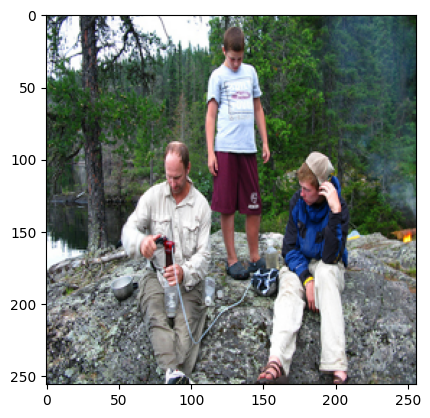

In [35]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_comment_length=80
image_name=folder_path + "/" + train_df['image_name'].iloc[1000]
# image_name='/content/1003420127.jpg'
image=Image.open(image_name).convert("RGB").resize((256,256))
image_array=np.array(image)
plt.imshow(image_array)
image_array=image_array / 255.0
image_array=image_array.reshape((1,256,256,3))
in_text='startseq'

sentence=[]
for i in range(20):
    seq = tokenizer.texts_to_sequences([in_text])
    padded_seq = pad_sequences(seq, maxlen=max_comment_length, padding="post")
    batch_output = model.predict([image_array, padded_seq])
    output = batch_output[0]

    index = np.argmax(output[i+1])
    if index != 0:
        word = tokenizer.index_word[index]

    in_text = in_text + " " + word
    print(in_text)
    sentence.append(word)
    if word == "endseq":
        break


In [25]:
print(' '.join(sentence))

woman three dog people in group older a a two


In [ ]:
  train_generator= generate_batches(train_df,batch_size=1)

  for (image_input, text_input) , target  in train_generator:
    print(image_input)
    print('\n\n\n')
    print(text_input)
    print('\n\n\n')
    print(target)
    break